# Lab 5 - Double descent on MNIST
Reproduction of Belkin, Hsu, Ma, Mandal (2018), *Reconciling modern machine-learning practice and the bias-variance trade-off*, Appendix C.3 (fully connected network with one hidden layer, Fig. 4 / Fig. 9).

**Note on the workflow.** The experiments take hours, so they are *not* run in this notebook. They were run by `run_experiments.py` (resumable, 2 background CPU workers), which stores one `results/<job>/rows.jsonl` per sweep (+ `config.json`). This notebook defines the model exactly as it is used in the script (for exercise 1b, with a quick sanity check) and then loads and analyses the saved results.

## 1a. Experimental assumptions in the paper that may influence the results

| Assumption (C.3 / Sec. 4) | Why it matters | Where we test it |
|---|---|---|
| **n = 4000 random MNIST samples** (paper: 4·10³), d=784, K=10 | The interpolation threshold is at `n·K` parameters, so the peak position depends on n; the particular subset changes the curve. | other subsets (`abl_subset*`) |
| **One hidden layer, width H**; N = (d+1)H + (H+1)K parameters | Threshold at N = nK = 40000, i.e. **H ≈ 50**. Activation not stated (we use ReLU as in the "ReLU features" in the paper). | sigmoid / tanh |
| **Squared loss** on one-hot labels | The theory (min-norm interpolation) is for squared loss; cross-entropy never reaches exactly 0 loss. | cross-entropy |
| **SGD, momentum 0.95**; step size and batch size not given | Determines which interpolating solution is found and whether training converges. | momentum, lr, batch size |
| **6000 epochs** (or until zero training error, only below threshold) | Near the threshold, interpolation needs a long training; stop too early and the peak disappears / moves. | 100, 400, 2000 vs 6000 epochs |
| **Step decay 10 % every 500 epochs** below threshold, constant above | Helps small nets converge. | (scaled as epochs/12 in the shorter runs) |
| **Weight reuse** in the under-parametrised regime (first H1 units copied, new weights N(0, 0.01)) | Makes training loss decrease monotonically with capacity; Fig. 9c shows that without it the variance is larger. | no weight reuse |
| **Init**: Glorot-uniform for the smallest net, standard random init above the threshold | Affects the interpolating solution reached by SGD. | Kaiming init |
| **Preprocessing**: pixels in [0,1], one-hot labels; metric zero-one and squared loss | Input scale interacts with the step size. | - |
| **Evaluation on the 10k MNIST test set** | Test error estimate is precise (~0.3 % std). | - |
| **Single run** per width (paper shows one curve) | Peak height has run-to-run variability. | seeds |

The paper has **no label noise** in this experiment; we add it in 1f.

Unspecified choices that we had to make: batch size 128, step size 0.01, ReLU, random subset seed 0, variance 0.01 -> std 0.1 for the new weights.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

RES = Path("results")
K, D, N_TRAIN = 10, 784, 4000
H_STAR = (N_TRAIN*K - K)/(D + 1 + K)
def n_params(h): return (D+1)*h + (h+1)*K
print(f"interpolation threshold: n*K = {N_TRAIN*K} params -> H* = {H_STAR:.1f}")

def load(name):
    d = pd.read_json(RES/name/"rows.jsonl", lines=True).sort_values("hidden").reset_index(drop=True)
    return d
def cfg(name): return json.load(open(RES/name/"config.json"))
status = pd.DataFrame([dict(job=p.name, widths=len(load(p.name)), done=(p/"DONE").exists()) for p in sorted(RES.iterdir())])
status.T

interpolation threshold: n*K = 40000 params -> H* = 50.3


,0,1,2,3,4,5,6,7,8,9,...,11,12,13,14,15,16,17,18,19,20
job,abl_baseline,abl_bs1000,abl_bs32,abl_cross_entropy,abl_epochs_100,abl_epochs_400,abl_kaiming,abl_lr_large,abl_lr_small,abl_no_momentum,...,abl_seed1,abl_seed2,abl_seed3,abl_sigmoid,abl_subset1,abl_subset2,abl_tanh,main,noise_0.1,noise_0.2
widths,15,15,15,15,15,15,15,15,15,15,...,15,15,15,15,15,15,15,25,25,25
done,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


## 1b. Fully connected network with one hidden layer of configurable width
Exactly the class used inside `run_experiments.py` (including the weight-reuse helper).

In [2]:
import torch, torch.nn as nn
ACTS = {"relu": nn.ReLU, "sigmoid": nn.Sigmoid, "tanh": nn.Tanh}

class MLP(nn.Module):
    """784 -> hidden -> 10, width configurable."""
    def __init__(self, hidden, act="relu", init="glorot"):
        super().__init__()
        self.hidden, self.act_name = hidden, act
        self.fc1, self.act, self.fc2 = nn.Linear(D, hidden), ACTS[act](), nn.Linear(hidden, K)
        for m in (self.fc1, self.fc2):
            if init == "glorot": nn.init.xavier_uniform_(m.weight)
            elif init == "normal": nn.init.normal_(m.weight, 0, 0.1)      # variance 0.01 (paper)
            elif init == "kaiming": nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
            nn.init.zeros_(m.bias)
    def forward(self, x): return self.fc2(self.act(self.fc1(x)))

def grow(small, hidden):
    """weight reuse: first H1 units from the trained smaller net, rest ~ N(0, 0.01)"""
    big, h = MLP(hidden, small.act_name, "normal"), small.hidden
    with torch.no_grad():
        big.fc1.weight[:h] = small.fc1.weight; big.fc1.bias[:h] = small.fc1.bias
        big.fc2.weight[:, :h] = small.fc2.weight; big.fc2.bias.copy_(small.fc2.bias)
    return big

for h in (3, 50, 800):
    m = MLP(h)
    assert sum(p.numel() for p in m.parameters()) == n_params(h)
    print(f"H={h:4d}: {n_params(h):7d} parameters (n*K = {N_TRAIN*K}) ", m(torch.rand(2, D)).shape)

H=   3:    2395 parameters (n*K = 40000)  torch.Size([2, 10])
H=  50:   39760 parameters (n*K = 40000)  torch.Size([2, 10])
H= 800:  636010 parameters (n*K = 40000)  torch.Size([2, 10])


Training protocol used in the script (paper-faithful where specified): squared loss on one-hot targets, SGD with momentum 0.95, lr 0.01, batch 128, **6000 epochs**; for H below the threshold the step size is decayed by 10 % every 500 epochs and training stops as soon as the training error is 0; above the threshold constant step size and the full 6000 epochs; weight reuse below the threshold. Training/test errors are computed at the end of training on the 4000 training samples and the full 10 000-image test set.

## 1c. Layer sizes from 3 to 800 (25 widths, denser around H ≈ 50)

In [3]:
main = load("main")
print(cfg("main")["widths"])
main[["hidden","n_params","epochs_run","train_err","test_err","train_sq","test_sq"]].round(4)

[3, 5, 8, 12, 16, 20, 25, 30, 35, 40, 45, 50, 55, 60, 70, 80, 100, 130, 170, 220, 300, 400, 550, 700, 800]


,hidden,n_params,epochs_run,train_err,test_err,train_sq,test_sq
0,3,2395,6000,0.7728,0.7884,0.7848,0.7983
1,5,3985,6000,0.5745,0.6077,0.5987,0.6542
2,8,6370,6000,0.2957,0.3757,0.3232,0.5116
3,12,9550,6000,0.0240,0.2020,0.0756,0.4812
4,16,12730,6000,0.0192,0.2180,0.0623,0.5882
5,20,15910,6000,0.0180,0.2310,0.0551,0.6756
6,25,19885,6000,0.0162,0.2303,0.0440,0.6824
7,30,23860,6000,0.0145,0.2362,0.0361,0.7335
8,35,27835,6000,0.0143,0.2509,0.0295,0.8186
9,40,31810,6000,0.0117,0.2555,0.0253,0.9096


## 1d. Training and test error vs. hidden layer size

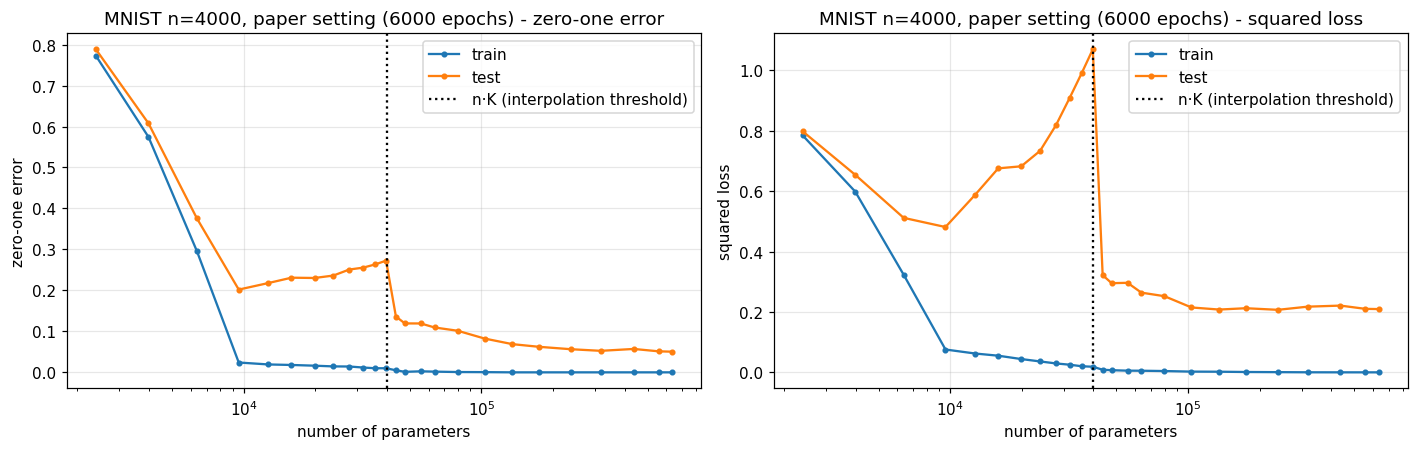

peak test error 0.273 at H=50 (39760 params); best classical (under-param.) test error 0.202 at H=12; test error at H=800: 0.0504
first width with train error exactly 0: 170


In [4]:
def plot_sweep(d, title, axs=None):
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, (m, lab) in zip(axs, [("err", "zero-one error"), ("sq", "squared loss")]):
        ax.plot(d.n_params, d[f"train_{m}"], "o-", ms=3, label="train")
        ax.plot(d.n_params, d[f"test_{m}"], "o-", ms=3, label="test")
        ax.axvline(N_TRAIN*K, color="k", ls=":", label="n·K (interpolation threshold)")
        ax.set_xscale("log"); ax.set_xlabel("number of parameters"); ax.set_ylabel(lab)
        ax.set_title(f"{title} - {lab}"); ax.legend()
    plt.tight_layout(); plt.show()
plot_sweep(main, "MNIST n=4000, paper setting (6000 epochs)")

pk = main.loc[main[main.hidden >= 16].test_err.idxmax()]
under = main[main.n_params < N_TRAIN*K]
print(f"peak test error {pk.test_err:.3f} at H={int(pk.hidden)} ({int(pk.n_params)} params); "
      f"best classical (under-param.) test error {under.test_err.min():.3f} at H={int(under.hidden[under.test_err.idxmin()])}; "
      f"test error at H=800: {main.test_err.iloc[-1]:.4f}")
print("first width with train error exactly 0:", int(main[main.train_err==0].hidden.min()))

### Observations (compare with Fig. 4 / 9a of the paper)
**Similarities.**
- The test curve has the characteristic **double descent**: it first decreases (classical regime, minimum around H≈12-16, i.e. ~20 % error at this size), rises to a **sharp peak at H≈50, exactly where N ≈ n·K = 40000**, and then drops again as H grows, ending **well below the best classical value** (≈5-6 % vs ≈20 %).
- The training zero-one error decreases with H (monotone because of weight reuse) and reaches ~0 right around the threshold; beyond it the network interpolates.
- The squared-loss panel shows the same shape, with an even more pronounced peak (the paper shows the same behaviour for the squared loss).

**Differences / caveats.**
- The peak is **not at a higher error than the paper's**: in our run the test error rises *gradually* from 20 % (H=12) to 27 % (H=50) and then **drops abruptly** between H=50 and H=55 (27 % -> 14 %). The paper's curve is a smoother, narrower bump. The abrupt drop coincides with the point where the protocol switches (below the threshold: weight reuse + step decay + early stopping; above it: fresh initialisation). The ablations below show that the weight-reuse chain is responsible for a large part of this rise (every network inherits the previous one's weights and is trained again, so small networks are effectively trained for many more epochs and over-fit more).
- The training error does not reach *exactly* 0 at the threshold: it is 1 % at H=50, 0.1 % at H=60 and exactly 0 only from H=170. In the paper the zero-one training error also only vanishes shortly after the threshold, but our approach to zero is slower (squared loss with lr 0.01 and a fixed 6000-epoch budget).
- Unspecified details (batch size 128, lr 0.01, ReLU, our random subset) differ from the paper's, so absolute levels differ; the location of the transition (N = nK, H≈50) matches the prediction.

## 1e. Ablations
Each assumption from 1a is changed one at a time. To save compute, ablations use a **reduced budget** (2000 epochs, coarser 15-width grid, step decay every epochs/12) and are compared to their own baseline `abl_baseline` run with the same budget (so all differences are due to the changed factor).

In [5]:
ABL = {"baseline (2000 ep)": "abl_baseline", "no weight reuse": "abl_no_reuse", "cross-entropy": "abl_cross_entropy",
       "sigmoid": "abl_sigmoid", "tanh": "abl_tanh", "100 epochs": "abl_epochs_100", "400 epochs": "abl_epochs_400",
       "no momentum (lr .2)": "abl_no_momentum", "small lr (.002)": "abl_lr_small", "large lr (.04)": "abl_lr_large",
       "Kaiming init": "abl_kaiming", "batch 32 (1000 ep)": "abl_bs32", "batch 1000": "abl_bs1000"}
ABL = {k: v for k, v in ABL.items() if (RES/v/"DONE").exists()}
abl = {k: load(v) for k, v in ABL.items()}
abl["main (6000 ep, finer grid)"] = main

def compare(runs, title, keys=None, metric="err"):
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
    for name, d in runs.items():
        if keys and name not in keys: continue
        l, = axs[0].plot(d.n_params, d[f"test_{metric}"], "o-", ms=3, label=name)
        axs[1].plot(d.n_params, d[f"train_{metric}"], "o-", ms=3, color=l.get_color(), label=name)
    for ax, t in zip(axs, ["test", "train"]):
        ax.axvline(N_TRAIN*K, color="k", ls=":"); ax.set_xscale("log")
        ax.set_xlabel("number of parameters"); ax.set_ylabel(f"{t} {'zero-one error' if metric=='err' else 'squared loss'}")
        ax.set_title(f"{title}: {t}")
    axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

def summary(runs):
    rows = {}
    for n, d in runs.items():
        u = d[d.n_params < N_TRAIN*K]; i = d[d.hidden >= 16].test_err.idxmax()   # peak searched for H>=16 (H=3 is trivially bad)
        rows[n] = dict(peak_test_err=d.test_err[i], peak_at_H=int(d.hidden[i]), best_underparam=u.test_err.min(), drop_50_to_55=(d.set_index("hidden").test_err.get(50, np.nan) - d.set_index("hidden").test_err.get(55, np.nan)),
                       test_err_H800=d.test_err.iloc[-1], train_err_H800=d.train_err.iloc[-1],
                       min_train_err_below_thr=u.train_err.min(), non_monotone_train=int((u.train_err.diff() > 0.005).sum()))
    return pd.DataFrame(rows).T.round(4)

### Weight reuse, loss function, activation

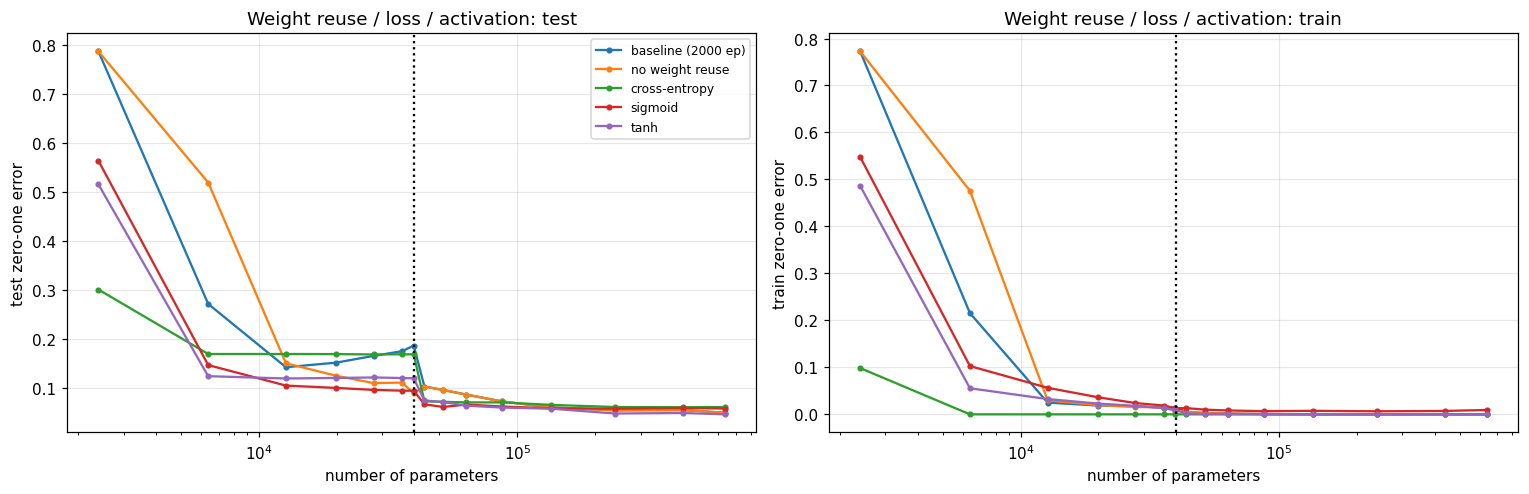

,peak_test_err,peak_at_H,best_underparam,drop_50_to_55,test_err_H800,train_err_H800,min_train_err_below_thr,non_monotone_train
baseline (2000 ep),0.1860,50.0,0.1419,0.0835,0.0489,0.0000,0.0145,0.0
no weight reuse,0.1501,16.0,0.0888,-0.0137,0.0489,0.0000,0.0075,0.0
cross-entropy,0.1689,16.0,0.1680,0.0961,0.0605,0.0000,0.0000,0.0
sigmoid,0.1044,16.0,0.0939,0.0278,0.0574,0.0093,0.0130,0.0
tanh,0.1210,35.0,0.1189,0.0453,0.0456,0.0000,0.0095,0.0


In [6]:
compare(abl, "Weight reuse / loss / activation", keys=["baseline (2000 ep)", "no weight reuse", "cross-entropy", "sigmoid", "tanh"])
summary({k: abl[k] for k in ["baseline (2000 ep)", "no weight reuse", "cross-entropy", "sigmoid", "tanh"] if k in abl})

### Number of training epochs (100 / 400 / 2000 / 6000)

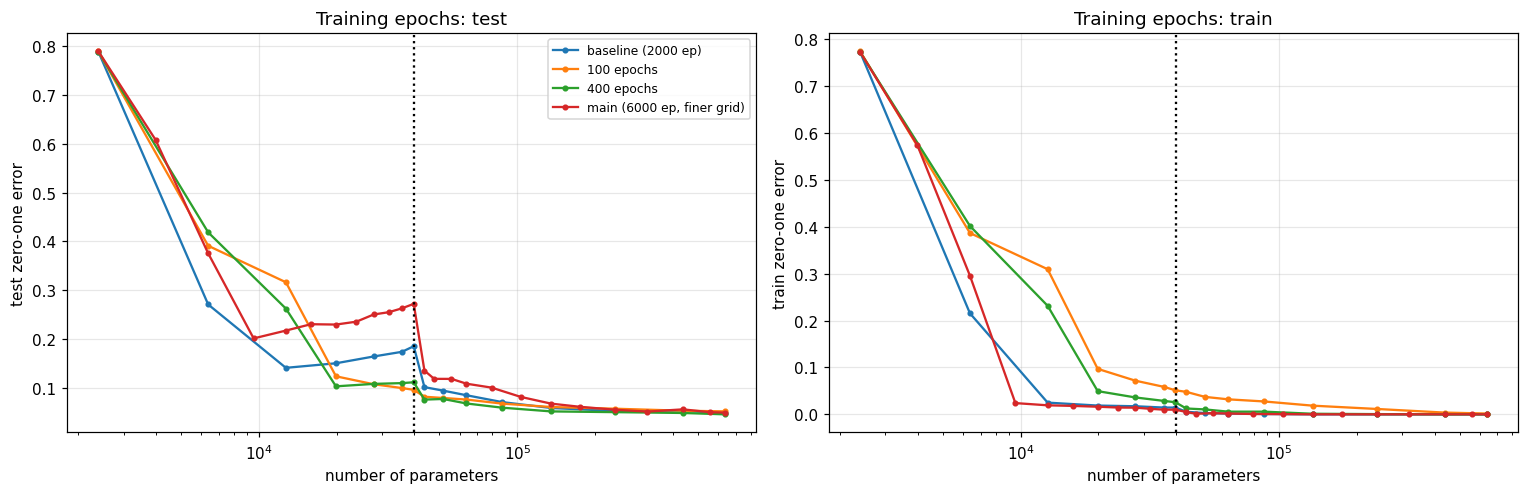

,peak_test_err,peak_at_H,best_underparam,drop_50_to_55,test_err_H800,train_err_H800,min_train_err_below_thr,non_monotone_train
100 epochs,0.3167,16.0,0.0970,0.0141,0.0530,0.0018,0.0512,0.0
400 epochs,0.2629,16.0,0.1041,0.0354,0.0469,0.0000,0.0258,0.0
baseline (2000 ep),0.1860,50.0,0.1419,0.0835,0.0489,0.0000,0.0145,0.0
"main (6000 ep, finer grid)",0.2726,50.0,0.2020,0.1364,0.0504,0.0000,0.0100,0.0


In [7]:
compare(abl, "Training epochs", keys=["100 epochs", "400 epochs", "baseline (2000 ep)", "main (6000 ep, finer grid)"])
summary({k: abl[k] for k in ["100 epochs", "400 epochs", "baseline (2000 ep)", "main (6000 ep, finer grid)"] if k in abl})

### Optimiser: momentum, step size, batch size; and initialisation

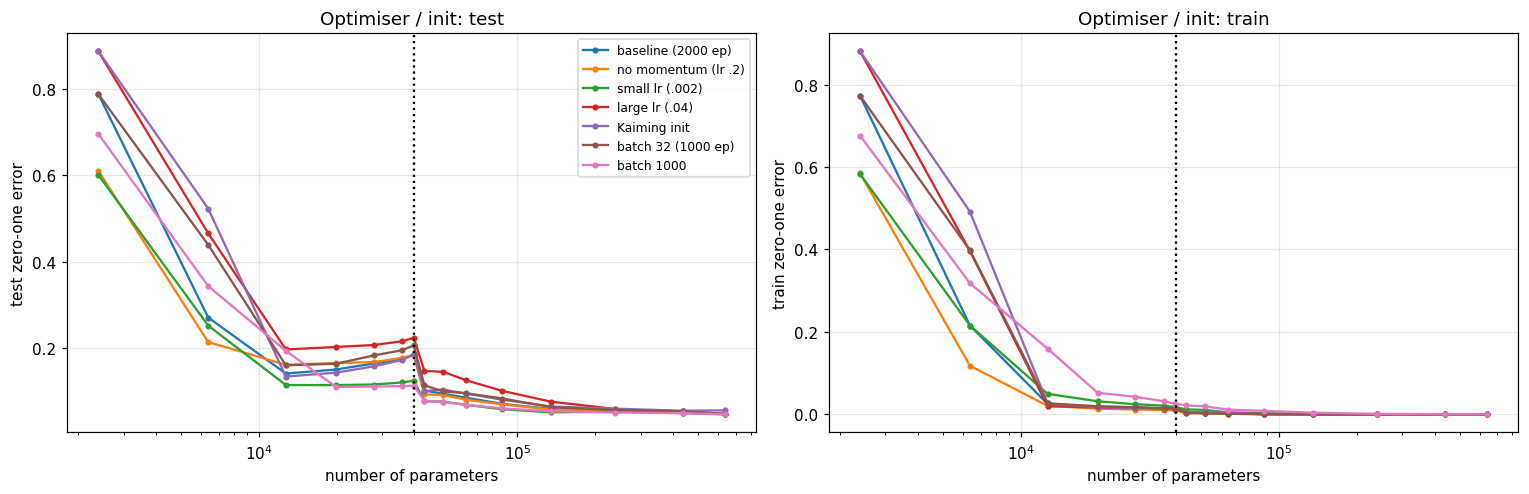

,peak_test_err,peak_at_H,best_underparam,drop_50_to_55,test_err_H800,train_err_H800,min_train_err_below_thr,non_monotone_train
baseline (2000 ep),0.1860,50.0,0.1419,0.0835,0.0489,0.0000,0.0145,0.0
no momentum (lr .2),0.1839,50.0,0.1620,0.0902,0.0487,0.0000,0.0095,0.0
small lr (.002),0.1255,50.0,0.1152,0.0477,0.0476,0.0000,0.0178,0.0
large lr (.04),0.2244,50.0,0.1975,0.0765,0.0482,0.0000,0.0140,0.0
batch 32 (1000 ep),0.2068,50.0,0.1609,0.0923,0.0484,0.0000,0.0137,0.0
batch 1000,0.1943,16.0,0.1109,0.0350,0.0478,0.0003,0.0258,0.0
Kaiming init,0.1859,50.0,0.1349,0.0844,0.0569,0.0000,0.0135,0.0


In [8]:
compare(abl, "Optimiser / init", keys=["baseline (2000 ep)", "no momentum (lr .2)", "small lr (.002)", "large lr (.04)",
                                        "batch 32 (1000 ep)", "batch 1000", "Kaiming init"])
summary({k: abl[k] for k in ["baseline (2000 ep)", "no momentum (lr .2)", "small lr (.002)", "large lr (.04)", "batch 32 (1000 ep)", "batch 1000", "Kaiming init"] if k in abl})

### Randomness: initialisation seeds and different 4000-sample subsets

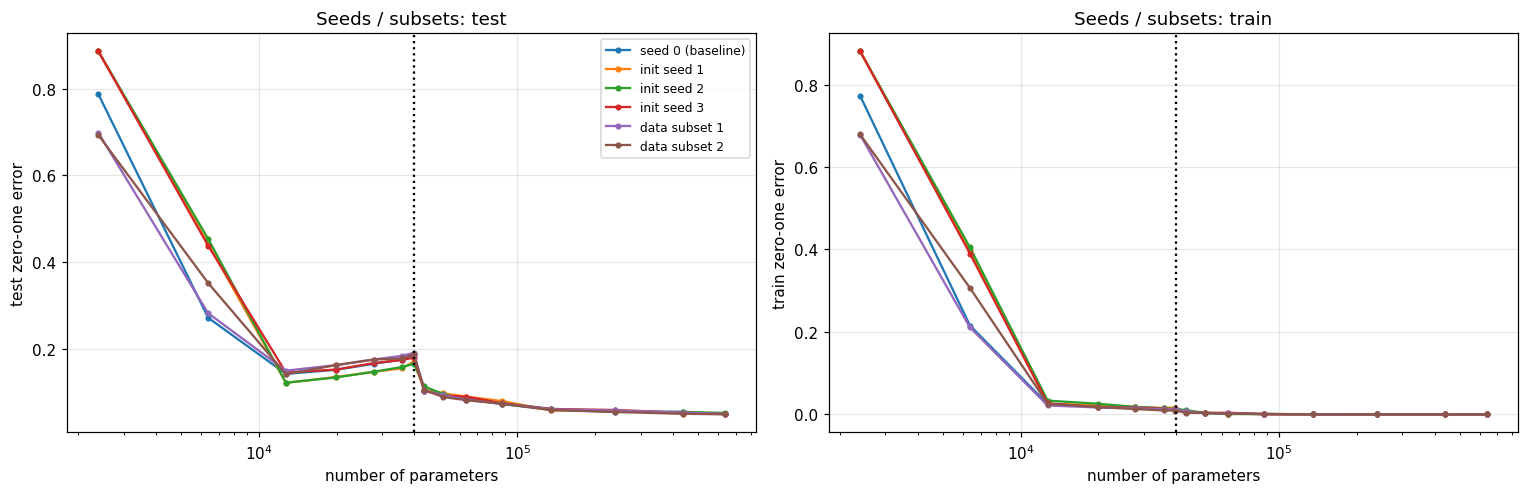

,peak_test_err,peak_at_H,best_underparam,drop_50_to_55,test_err_H800,train_err_H800,min_train_err_below_thr,non_monotone_train
seed 0 (baseline),0.1860,50.0,0.1419,0.0835,0.0489,0.0,0.0145,0.0
init seed 1,0.1700,50.0,0.1211,0.0655,0.0495,0.0,0.0155,0.0
init seed 2,0.1651,50.0,0.1215,0.0524,0.0518,0.0,0.0135,0.0
init seed 3,0.1792,50.0,0.1451,0.0763,0.0490,0.0,0.0120,0.0
data subset 1,0.1904,50.0,0.1492,0.0871,0.0495,0.0,0.0120,0.0
data subset 2,0.1871,50.0,0.1412,0.0826,0.0484,0.0,0.0090,0.0


std of peak height across the 4 init seeds: 0.0093
std of test error at H=800: 0.0012


In [9]:
seedruns = {"seed 0 (baseline)": load("abl_baseline")}
for s in (1, 2, 3): seedruns[f"init seed {s}"] = load(f"abl_seed{s}")
for s in (1, 2): seedruns[f"data subset {s}"] = load(f"abl_subset{s}")
compare(seedruns, "Seeds / subsets")
S = summary(seedruns); display(S)
print("std of peak height across the 4 init seeds:", S.loc[[i for i in S.index if 'seed' in i], "peak_test_err"].std().round(4))
print("std of test error at H=800:", S.test_err_H800.std().round(4))

### Observations on the ablations

**Summary table above (peak = max test error for H>=16; `drop_50_to_55` = test error at H=50 minus at H=55).** Reduced budget: 2000 epochs; compare each row to *baseline (2000 ep)*.

- **Weight reuse (most important finding).** Without weight reuse the sharp peak almost disappears: test error is ~11 % at H=35-45, 8.9 % at H=50 and 10.2 % at H=55 and then decays smoothly to 4.9 %; the training error is however monotone as well, and the over-parametrised part (H>=55) is identical to the baseline (same procedure there). So in our implementation the *rise* of the test error in the classical regime is largely produced by the chained, repeated training of the weight-reuse scheme, and the double descent appears in a weaker form (noisier curve, bump around H=45-55 compared to H=35) - qualitatively consistent with the paper's statement that Fig. 9c is noisier but still shows double descent, but weaker than in the paper.
- **Loss function.** With cross-entropy there is **no peak**: the network reaches 0 training error already at H=8 (the loss can be driven to 0 with a large margin, also for few parameters) and the stop-at-zero rule then freezes the model, so test error is flat (16.8 %) below the threshold and 6-7 % above; the jump at H=55 is again the protocol switch. Squared loss is the setting where the interpolation threshold N=nK is meaningful, as in the paper.
- **Activation.** Sigmoid and tanh show a much weaker bump (sigmoid: 9.4 % at H=50 vs 10.0 at 25; tanh: flat 12 %) and then still a drop at H=55 (to ~7 %). The location of the transition is unchanged (set by the parameter count), the height depends strongly on the activation. Sigmoid also does not fully interpolate at 2000 epochs (training error stays ~0.7-0.9 %).
- **Number of epochs.** With 100 epochs (not enough to fit the data: training error 5 % at H=50, 0.18 % at H=800) and 400 epochs the bump is much smaller (9.7 % and 11.2 % at H=50 vs 18.6 % with 2000 and 27 % with 6000 epochs): **the peak grows with the training time** because the networks close to the threshold are forced to interpolate with very large weights; with too little training they do not interpolate and behave like early-stopped, regularised models (note that test error at H=800 is nearly unchanged, 4.7-5.3 %). This confirms the paper's choice of 6000 epochs.
- **Optimisation (momentum, step size, batch size).** Without momentum (lr 0.2, same effective step) the result is practically the baseline. A smaller step (0.002) gives a flatter peak (12.5 %), a larger step (0.04) a higher peak (22.4 %); small batches (32) give a slightly higher peak (20.7 %), large batches (1000) a lower one (11.3 %) and slower fitting (training error 0.03 % at H=800). The existence of the drop at the threshold is always preserved, the height of the peak is an optimiser-dependent quantity (implicit regularisation of SGD).
- **Initialisation.** Kaiming normal gives essentially the same curve (peak 18.6 %), only the smallest nets are worse.
- **Seeds / subsets.** The peak height varies by a few points across init seeds (16.5-18.6 % at H=50 in the 2000-epoch setting, see the printed std below) and subsets (18.7-19.0 %), while the shape (rise, sudden drop at H=55, slow decay to ~4.9 % at H=800) is reproduced every time; the final test error at H=800 varies very little (printed std below).

## 1f. Label noise
A fraction `p` of the 4000 training labels is replaced by a different random class (test labels are clean). Same protocol as the main experiment (6000 epochs, 25 widths). Train error is reported w.r.t. the noisy labels used for training, and also w.r.t. the true labels.

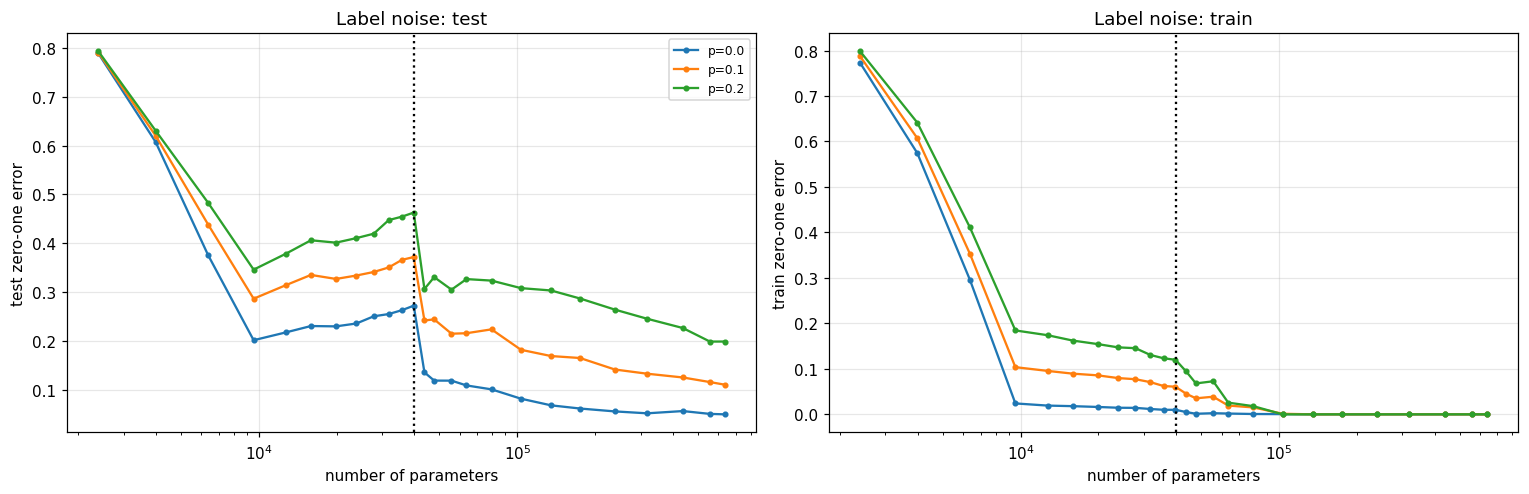

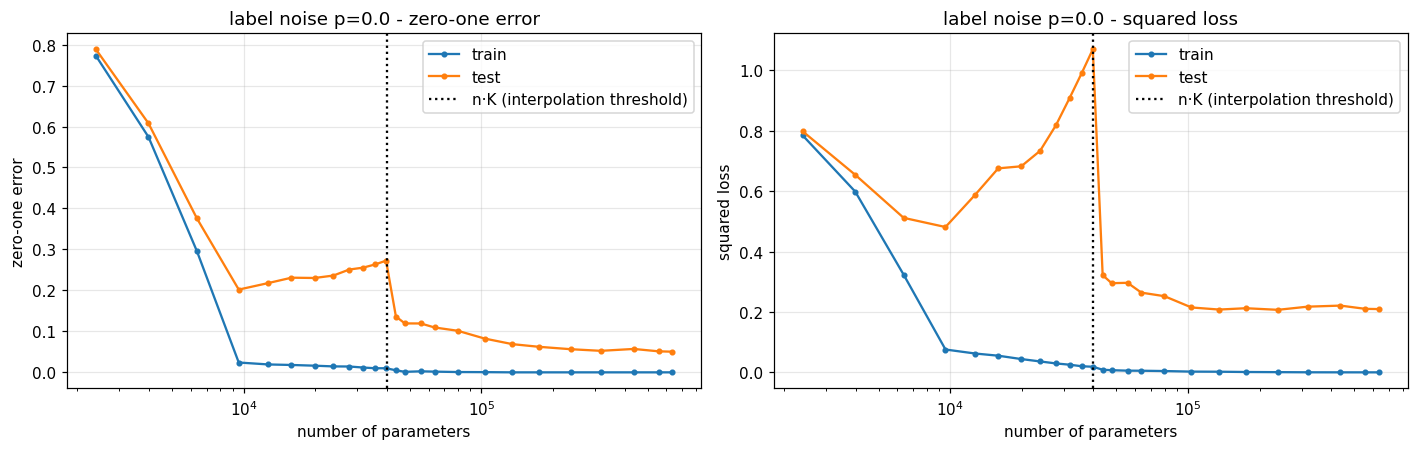

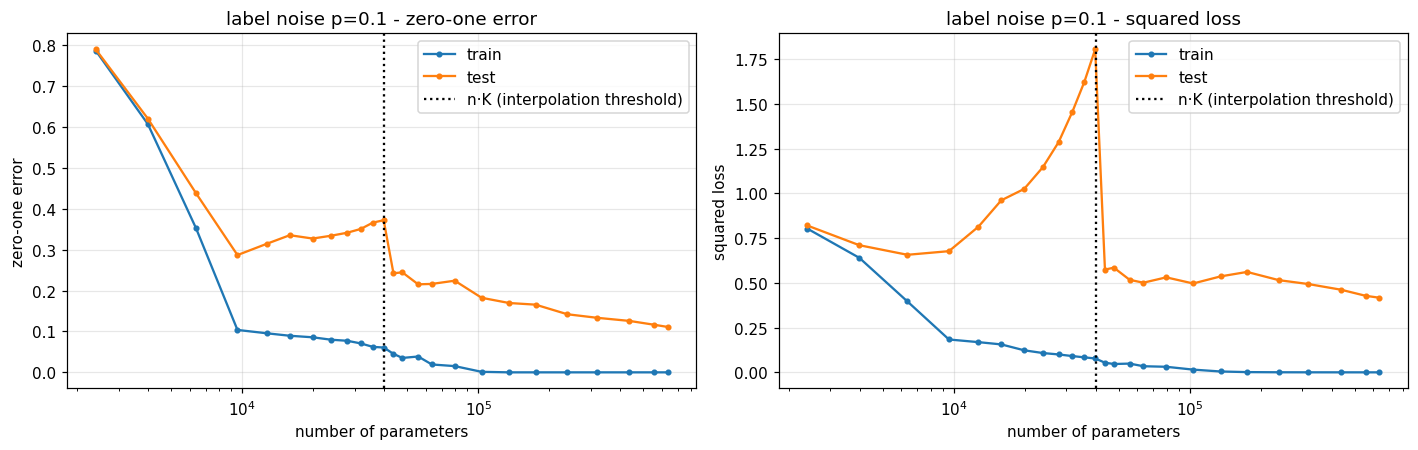

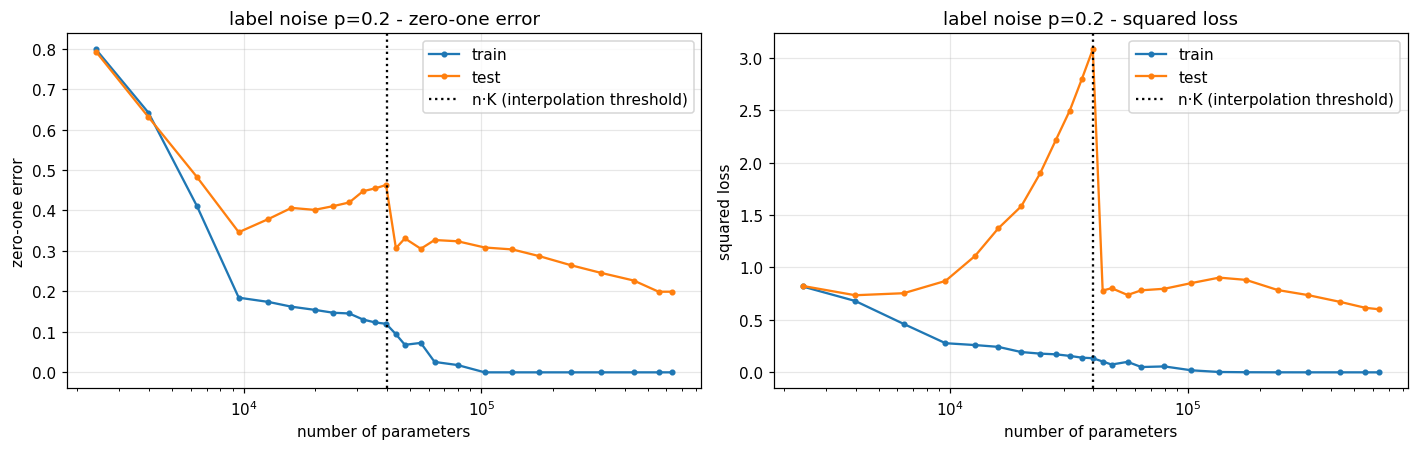

In [10]:
noise = {"p=0.0": main, "p=0.1": load("noise_0.1"), "p=0.2": load("noise_0.2")}
compare(noise, "Label noise")
for p, d in noise.items():
    plot_sweep(d, f"label noise {p}")

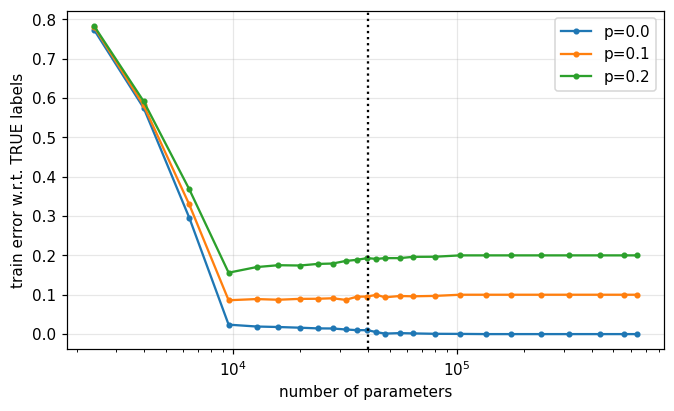

,peak_test_err,peak_at_H,best_underparam,drop_50_to_55,test_err_H800,train_err_H800,min_train_err_below_thr,non_monotone_train
p=0.0,0.2726,50.0,0.2020,0.1364,0.0504,0.0,0.0100,0.0
p=0.1,0.3721,50.0,0.2869,0.1297,0.1110,0.0,0.0608,0.0
p=0.2,0.4630,50.0,0.3463,0.1562,0.1993,0.0,0.1200,0.0


In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, d in noise.items():
    ax.plot(d.n_params, d.train_err_clean, "o-", ms=3, label=f"{name}")
ax.axvline(N_TRAIN*K, color="k", ls=":"); ax.set_xscale("log")
ax.set_xlabel("number of parameters"); ax.set_ylabel("train error w.r.t. TRUE labels"); ax.legend(); plt.show()
summary(noise)

### Observations on label noise

- **Peak vs. noise level.** The test error around the threshold rises with the amount of noise: peak (H=50) 27 % (p=0), 37 % (p=0.1), 46 % (p=0.2), and in all cases it falls again beyond the threshold (14 %, 24 %, 31 % at H=55). The drop is again sharp at the transition (see the weight-reuse caveat in 1e), and for noisy labels it is followed by a slow, clear decay: H=800 reaches 5.0 %, 11.1 % and 19.9 %, so the final error is roughly the clean error plus a penalty of 0.6-0.7 p; in the over-parametrised regime the network is much better than at the peak: at p=0.2 it beats the best classical model (34.6 % at H=12) by 15 points.
- **Interpolation of noise.** From H=130-170 the training error w.r.t. the *noisy* labels is exactly 0 for all noise levels (the nets memorise the wrong labels), while the error w.r.t. the *true* training labels equals p (0.100 and 0.200 at the right of the plot) - the network fits the corrupted samples with the wrong label. Despite this the test error stays moderate and keeps decreasing with H, so interpolating the noise does not destroy generalisation in the highly over-parametrised regime (the paper's claim).
- **Classical regime** (H<50): the training error w.r.t. true labels is ~ 0.09 for p=0.1, i.e. small nets cannot memorise the noise and fit mostly the clean structure, with the test error increasing as capacity grows (over-fitting the noise); the minimum of the classical regime is at small H=12 for all p, and moves in absolute value from 20 % to 29 % to 35 %.
- Compared with the paper (which only shows noise results in its appendix/other datasets) the effect is as expected: noise makes the peak much more pronounced while the over-parametrised regime still benefits from extra width.

## Conclusions
- A **double-descent curve** is reproduced on MNIST (n=4000) with a one-hidden-layer network: test error 20 % (best classical) -> 27 % peak at the interpolation threshold N=nK (H≈50) -> ~5 % at H=800, well below the best classical model, while the training error goes to 0.
- Several experimental details matter a lot: the **peak height and sharpness** depend on training time (long training is needed), on the loss (no peak for cross-entropy under our stopping rule), activation, step size/batch size and especially on the **weight-reuse scheme**, which in our implementation produces much of the sharp rise/drop; **the location** of the transition is robust (set by the parameter count), and so is the final over-parametrised performance (4.6-6 % for all variants).
- **Label noise** amplifies the peak (27 -> 37 -> 46 %) and the networks interpolate the corrupted labels exactly, yet their test error continues to decrease with width.
- Limitations: one run per width in the paper-faithful experiments, a reduced epoch budget (2000) and coarser grid for ablations, and unspecified paper hyperparameters (batch size, lr) chosen by us.